In [8]:
#This allows for the following data frames to be used in other notebooks without loading the dataset again.

%store train_df
%store validation_df
%store test_df
%store df

Stored 'train_df' (DataFrame)
Stored 'validation_df' (DataFrame)
Stored 'test_df' (DataFrame)
Stored 'df' (DataFrame)


In [2]:
from pathlib import Path
import pandas as pd

# Load the credit card dataset
csv_path = Path("../data/creditcard.csv")
if not csv_path.exists(): 
    csv_path = Path("data/creditcard.csv") # The loads the data set from the alternate path if the inital path fails.

if not csv_path.exists():
    raise FileNotFoundError(f"Credit card dataset not found at {csv_path}. Please ensure the dataset is available." 
    f"{Path('../data/creditcard.csv').resolve()} and {Path('data/creditcard.csv').resolve()}.")

df = pd.read_csv(csv_path)

exploratory_data_analysis = True  # Set to True to perform EDA, False to skip

# Check if the expected columns are present in the dataset
expected_columns = ["Time", [f"V{i}" for i in range(1, 29)], "Amount", "Class"]

print(f"Loaded: {csv_path.resolve()}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Columns match expected schema: {list(df.columns) == expected_columns}")
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
print(f"\nDuplicate rows: {df.duplicated().sum():,}")
print("\nClass counts:")
print(df["Class"].value_counts(dropna=False).sort_index())

print(f"\nExpected 284,807 rows: {len(df) == 284_807}")
print(f"Expected 492 fraud cases: {df['Class'].eq(1).sum() == 492}")

Loaded: C:\Users\user\Documents\AlgomaU courses\Computer Science\Third Year\Data Science with Python\Data Science Final Project\data\creditcard.csv
Shape: 284,807 rows × 31 columns
Columns match expected schema: False

Column types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0

### **Finds from exploratory analysis -->** 
1. _There appears to be about 1,081 duplicate rows._
2. _Using 0 to represent non fraud data and 1 to represent fraud data there are 284315 case and 492 case respectfully._
3. _There are no missing values in the data set._

In [6]:
#Data Splitting and Seeding 

import random
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# This splits 30% of the data then divides it into equal parts(15% - 15%) for validation and testing.
# The reason for this is to ensure that the model is evaluated on unseen data and to prevent overfitting.

train_dx, temp_dx = train_test_split(
    df.index,
    test_size=0.30, # The 30% for validation and testing
    stratify=df["Class"], # Ensures that the class distribution is preserved in the splits
    random_state=SEED
)

validation_dx, test_dx = train_test_split(
    temp_dx,
    test_size=0.50, # Split the 30% into 15% validation and 15% testing
    stratify=df.loc[temp_dx, "Class"], # This ensures that the class distribution is preserved within the 30% splits 
    random_state=SEED
)

train_df = df.loc[train_dx].copy() 
validation_df = df.loc[validation_dx].copy()
test_df = df.loc[test_dx].copy()

for name, split in [
    ("Train", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(split)} rows; "
        f"{split['Class'].sum():,} frauds "
        f"({split['Class'].mean() * 100:.4f}% of total)"
    )

Train: 199364 rows; 344 frauds (0.1725% of total)
Validation: 42721 rows; 74 frauds (0.1732% of total)
Test: 42722 rows; 74 frauds (0.1732% of total)


### **Notes from seeding and data split** 
1. _30% of the total data was split off to use for testing_
2. _The 30% was further split down to half [15-15] each for tesing and vaildation_
3. _The remaining 70% will used for model training._
4. _I also learnt the use of a seed and it implementation._

In [4]:
project_root = csv_path.parent.parent
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

split_path = results_dir / "split_indices.npz"
np.savez_compressed(
    split_path,
    train_idx=np.asarray(train_dx),
    validation_idx=np.asarray(validation_dx),
    test_idx=np.asarray(test_dx),
)

print(f"Saved split indices to: {split_path}")

Saved split indices to: ..\results\split_indices.npz


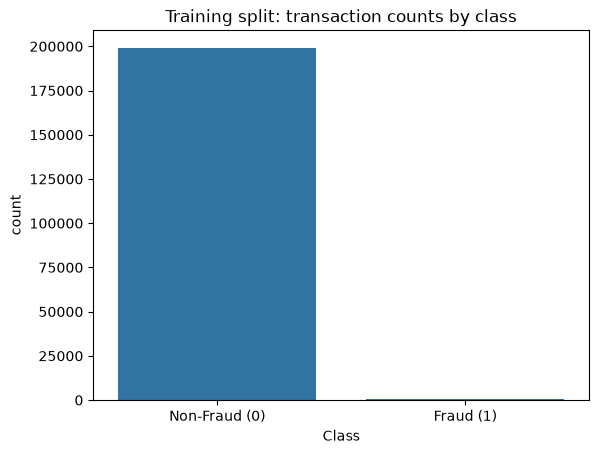

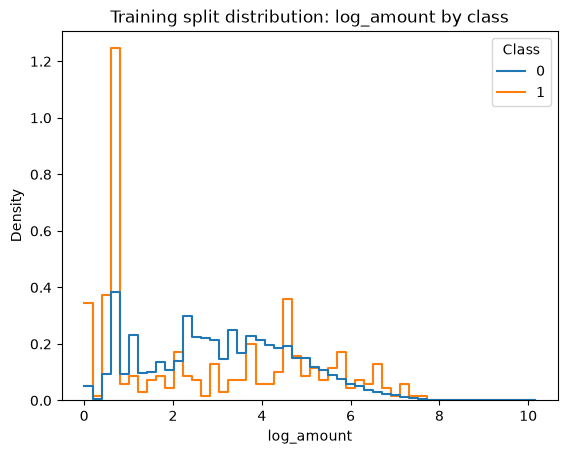

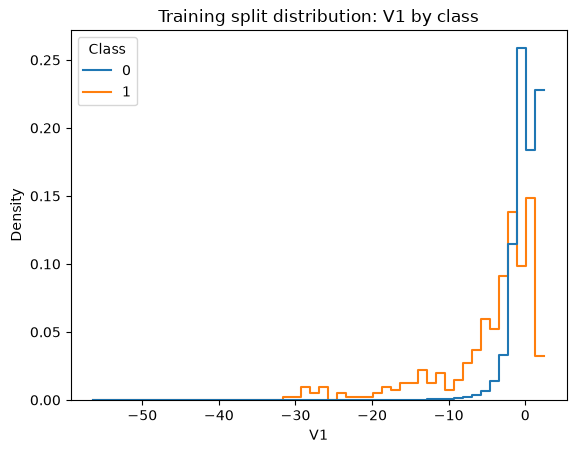

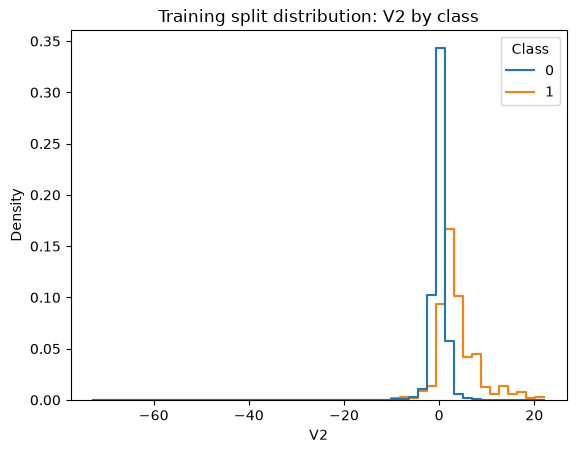

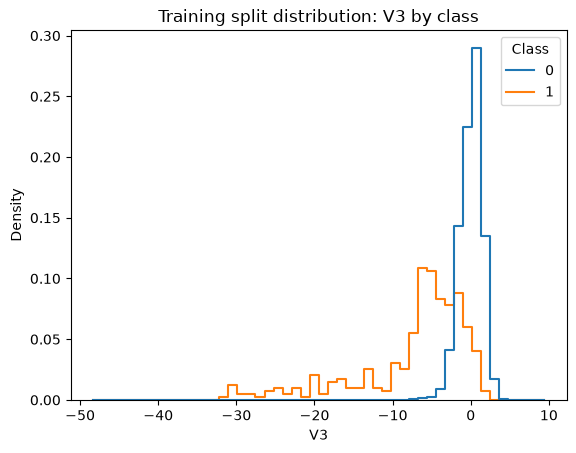

In [5]:
#Class imbalance and feature distribution checks
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data = train_df, x = "Class")
plt.title("Training split: transaction counts by class")
plt.xticks([0,1], ["Non-Fraud (0)", "Fraud (1)"])
plt.show()


train_df = train_df.assign(log_amount=np.log1p(train_df["Amount"]))

for feature in ["log_amount", "V1", "V2", "V3"]:
    sns. histplot(
        data=train_df,
        x=feature,
        hue="Class",
        bins=50,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
    )
    plt.title(f"Training split distribution: {feature} by class")
    plt.show()

### **Notes from class imbalance and features distribution**
1. _The first plot compares the distribution of transaction amounts for legitimate and fraudulent transactions after a log transformation; the transformation made ammount scale easier to inspect._

2. _The features distribution of [v1,v2,v3] compares between two transaaction classes to show where each values differs and overlap_